# P6 Morfologi dan Komponen Terhubung (Bagian 3, 4, 5)

In [1]:
# Persiapan (Kode 1.1 + fungsi tepi_canny dari Kode 1.3)
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from utils_cv import baca, tampil
except ImportError:
    def baca(path):
        return cv2.imread(path)

    def tampil(citra, judul, baris=1, ukuran=(14, 4)):
        kolom = int(np.ceil(len(citra) / baris))
        plt.figure(figsize=ukuran)
        for i, (c, j) in enumerate(zip(citra, judul)):
            plt.subplot(baris, kolom, i + 1)
            if c.ndim == 3:
                plt.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
            else:
                plt.imshow(c, cmap="gray")
            plt.title(j, fontsize=8); plt.axis("off")
        plt.show()
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")


def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

In [2]:
# Langkah 3.1 Verifikasi lembar hitung (SE persegi 3x3, luar citra = 0)
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
se3 = np.ones((3, 3), np.uint8)
kw = dict(borderType=cv2.BORDER_CONSTANT, borderValue=0)  # piksel di luar citra bernilai 0
erosi = cv2.erode(B, se3, **kw)
dilasi = cv2.dilate(B, se3, **kw)
opening = cv2.dilate(erosi, se3, **kw)
closing = cv2.erode(dilasi, se3, **kw)
closing_opening = cv2.dilate(cv2.erode(closing, se3, **kw), se3, **kw)

for k in [4, 8]:
    print(f"konektivitas {k}: {cv2.connectedComponents(B, connectivity=k)[0] - 1} komponen")
for nm, m in [("erosi", erosi), ("opening", opening), ("closing", closing), ("closing lalu opening", closing_opening)]:
    print(f"\n{nm}:\n{m}")

konektivitas 4: 4 komponen
konektivitas 8: 3 komponen

erosi:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

opening:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

closing:
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]

closing lalu opening:
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.997                   221               8           0.392
1  teh_021.png          0.997                   220               2           0.181
2  teh_011.png          0.998                   177               0               -


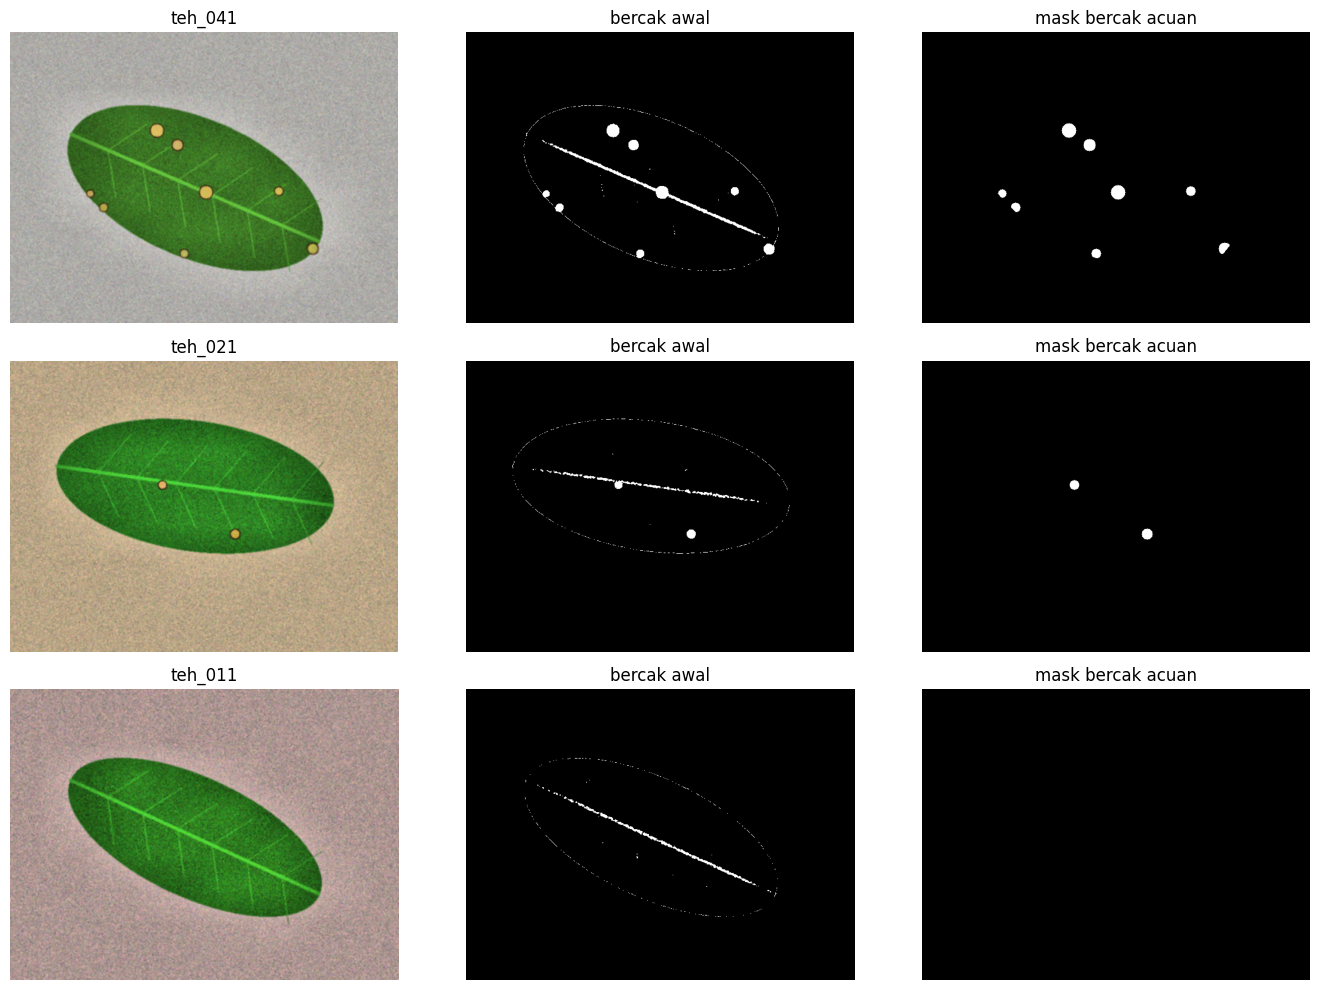

In [3]:
# Kode 3.1 Mask daun awal dan bercak awal
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1


baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

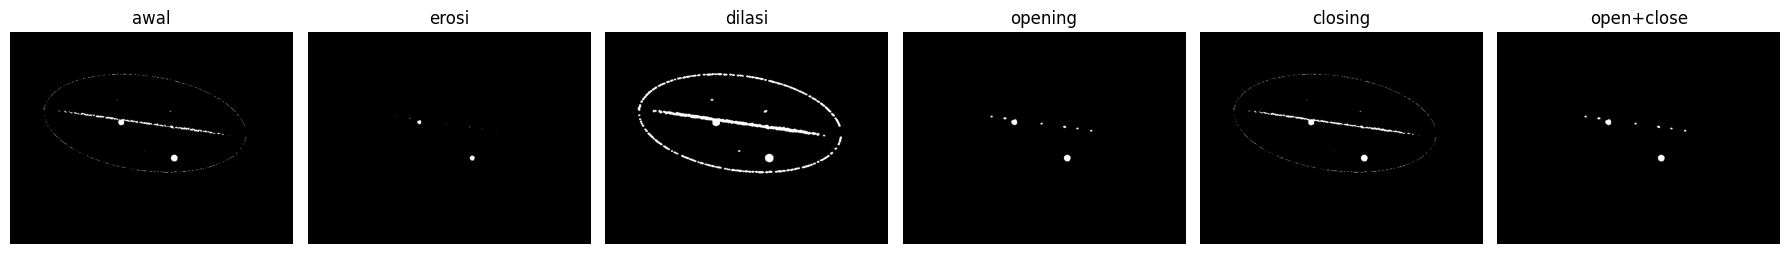

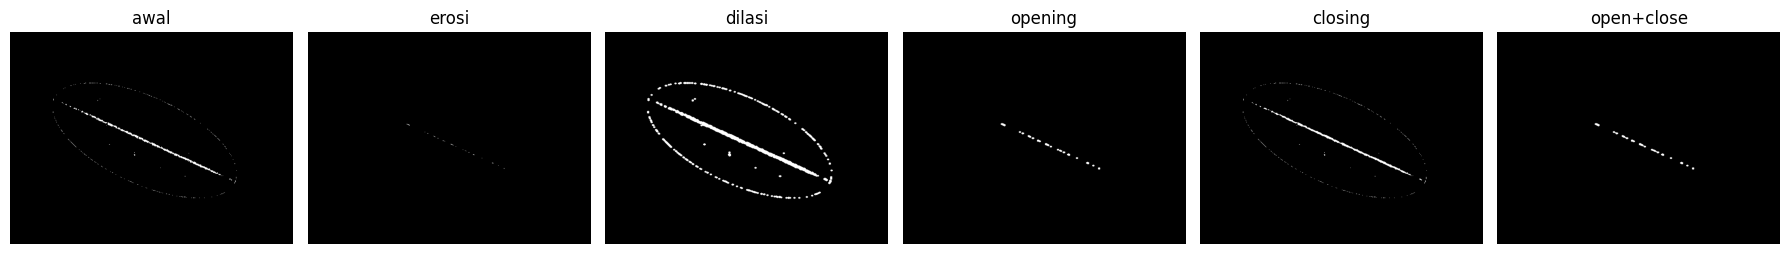

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       220    1718  0.181
1   teh_021.png       erosi         8     170  0.348
2   teh_021.png      dilasi        50    7014  0.064
3   teh_021.png     opening         8     439  0.551
4   teh_021.png     closing       202    1838  0.175
5   teh_021.png  open+close         8     439  0.551
6   teh_011.png        awal       177    1563      -
7   teh_011.png       erosi        19      47      -
8   teh_011.png      dilasi        68    6048      -
9   teh_011.png     opening        15     428      -
10  teh_011.png     closing       167    1708      -
11  teh_011.png  open+close        11     448      -


In [4]:
# Kode 3.2 Erosi, dilasi, opening, closing
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))


def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}


baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3)); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

In [5]:
# Kode 3.3 Eksperimen k, bentuk, dan ukuran SE
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

# Tabel 9 (k = 4)
t9 = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"]).round(2)
print(t9)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.62   0.16        14.30  17.25  29.20
          5       0.66   0.22         3.40   4.80   2.90
          7       0.73   0.46         1.75   1.35   2.30
  persegi 3       0.62   0.17         6.75   7.10   6.60
          5       0.68   0.32         2.50   4.55   3.05
          7       0.74   0.49         0.25   0.75   0.10
  silang  3       0.62   0.16        14.30  17.25  29.20
          5       0.66   0.22         5.80   8.00   5.35
          7       0.74   0.44         3.15   2.55   4.45
4 elips   3       0.67   0.25         7.85  13.85  14.60
          5       0.69   0.40         2.45   3.25   2.45
          7       0.73   0.49         0.40   0.85   0.75
  persegi 3       0.67   0.28         5.00   8.75   6.70
          5       0.71   0.47         1.45   0.85   1.80
          7       0.71   0.46  

In [6]:
# Kode 3.4 Gradien morfologi vs Canny (batas daun)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.806     0.704
gelap                          0.983     0.686
kontras_rendah                 0.208     0.908
normal                         0.990     0.684
terang                         0.953     0.701


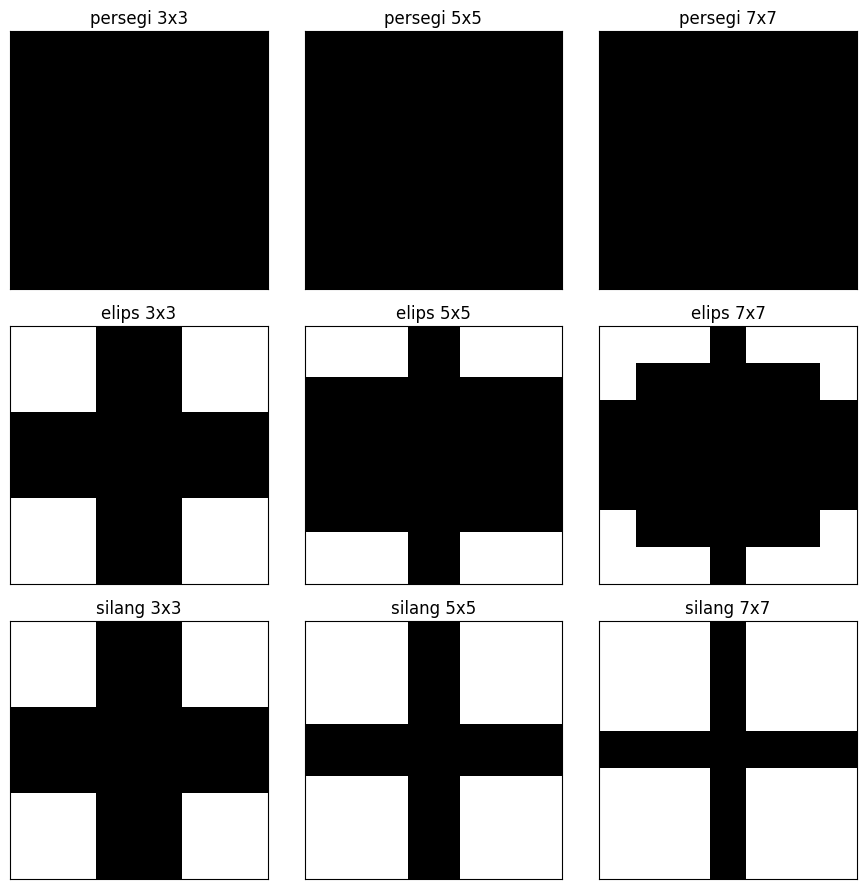

In [7]:
# Langkah 3.6 (Kerjakan sendiri) Panel SE persegi, elips, silang ukuran 3, 5, 7
plt.figure(figsize=(9, 9))
i = 1
for nb, kb in bentuk.items():
    for uk in [3, 5, 7]:
        plt.subplot(3, 3, i); i += 1
        plt.imshow(cv2.getStructuringElement(kb, (uk, uk)), cmap="gray_r", vmin=0, vmax=1)
        plt.title(f"{nb} {uk}x{uk}"); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", dpi=150); plt.show()

In [8]:
# Langkah 4.1 Verifikasi lembar hitung (bercak 3x3 padat dan garis 1x6)
MM_PER_PX = 0.4375


def keliling_sisi(m):
    """Jumlah sisi piksel objek yang berbatasan dengan latar (luar citra = latar)."""
    p = np.pad((m > 0).astype(int), 1)
    return int(sum(((p[1:-1, 1:-1] == 1) & (np.roll(p, s, axis=a)[1:-1, 1:-1] == 0)).sum()
                   for a in (0, 1) for s in (1, -1)))


for nm, (h, w) in [("bercak 3x3", (3, 3)), ("garis 1x6", (1, 6))]:
    m = np.ones((h, w), np.uint8)
    A_, K_ = int(m.sum()), keliling_sisi(m)
    print(f"{nm}: luas={A_} px = {A_ * MM_PER_PX ** 2:.3f} mm2, keliling={K_}, "
          f"kebulatan={4 * np.pi * A_ / K_ ** 2:.3f}, rasio aspek={max(h, w) / min(h, w):.2f}")

bercak 3x3: luas=9 px = 1.723 mm2, keliling=12, kebulatan=0.785, rasio aspek=1.00
garis 1x6: luas=6 px = 1.148 mm2, keliling=14, kebulatan=0.385, rasio aspek=6.00


konektivitas 4: 11 komponen
konektivitas 8: 11 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      370     70.82         69.9       0.95         1.10  242  162
1       2      239     45.75         54.6       1.01         1.00  275  185
2       3       26      4.98         17.1       1.12         1.00  163  195
3       4       92     17.61         51.5       0.44         5.14  179  202
4       5      461     88.24        214.3       0.13        18.43  239  228
5       6     1188    227.39        445.9       0.08         9.52  368  283
6       7      143     27.37         41.8       1.03         1.08  442  262
7       8      107     20.48         36.4       1.02         1.13  131  266
8       9      151     28.90         43.8       0.99         1.07  153  289
9      10      258     49.38         56.9       1.00         1.00  499  357
10     11      148     28.33         43.0       1.01         1.08  286  365


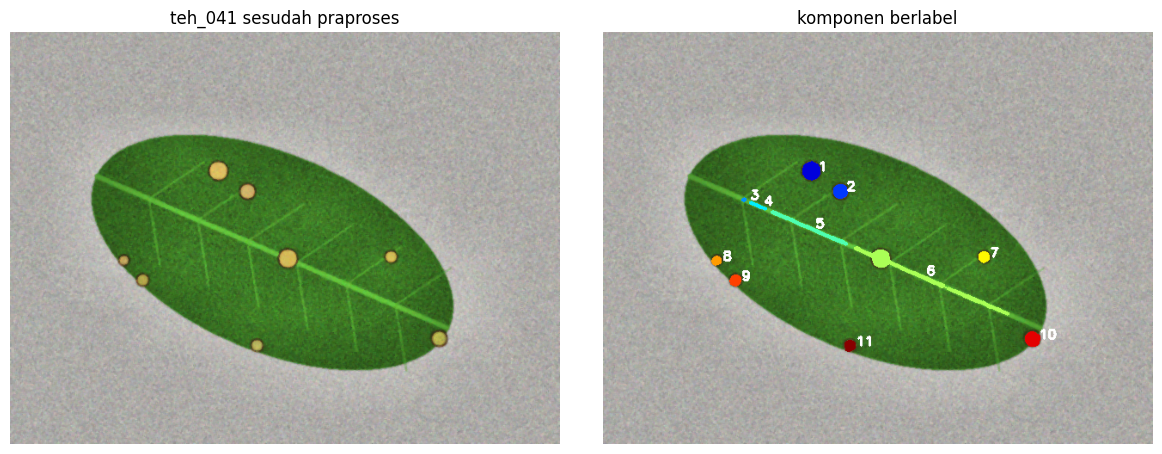

In [9]:
# Kode 4.1 Komponen terhubung dan pengukuran
def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl


img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

In [10]:
# Kode 4.2 Penyaringan komponen
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos


aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.70    1.60   0.85
luas + kebulatan + rasio   0.45    1.20   0.45
luas >= 20                 1.20    2.20   1.75
tanpa saring               2.45    3.25   2.45
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             8
luas + kebulatan + rasio     6
luas >= 20                  10
tanpa saring                11
Name: palsu, dtype: int64


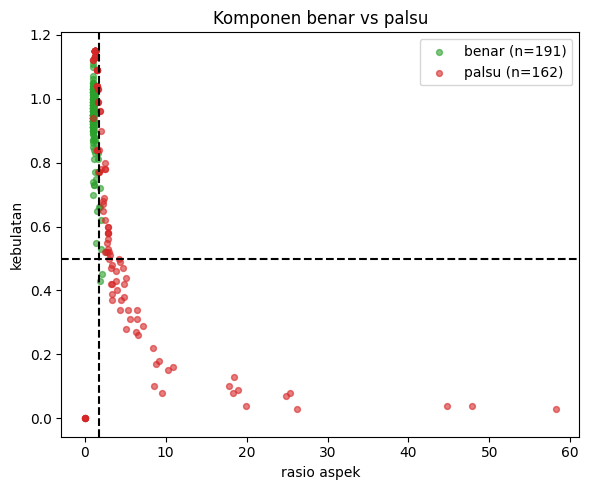

benar                False    True 
luas_px     count   162.00   191.00
            mean    128.35   320.36
            std     347.62   239.64
            min       1.00    22.00
            25%      17.00   126.50
            50%      27.00   250.00
            75%      53.75   487.50
            max    2393.00  1341.00
kebulatan   count   162.00   191.00
            mean      0.78     0.94
            std       0.41     0.11
            min       0.00     0.43
            25%       0.43     0.92
            50%       0.99     0.95
            75%       1.15     1.00
            max       1.15     1.13
rasio_aspek count   162.00   191.00
            mean      4.23     1.11
            std       7.89     0.23
            min       0.00     1.00
            25%       1.25     1.00
            50%       1.50     1.04
            75%       3.31     1.10
            max      58.20     2.60


In [11]:
# Langkah 4.4 (Kerjakan sendiri) Diagram sebar komponen benar vs palsu
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tk, lb = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        benar = (mb[lb == r.label] > 0).mean() > 0.5  # > separuh piksel berada di mask acuan
        baris.append([r.luas_px, r.kebulatan, r.rasio_aspek, benar])
kom = pd.DataFrame(baris, columns=["luas_px", "kebulatan", "rasio_aspek", "benar"])
plt.figure(figsize=(6, 5))
for flag, wr, nm in [(True, "tab:green", "benar"), (False, "tab:red", "palsu")]:
    s = kom[kom.benar == flag]
    plt.scatter(s.rasio_aspek, s.kebulatan, c=wr, label=f"{nm} (n={len(s)})", alpha=0.6, s=18)
plt.axhline(0.5, ls="--", c="k"); plt.axvline(1.8, ls="--", c="k")
plt.xlabel("rasio aspek"); plt.ylabel("kebulatan"); plt.legend(); plt.title("Komponen benar vs palsu")
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_komponen.png", dpi=150); plt.show()
print(kom.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe().T.round(2))

Galat absolut rerata persen bercak: 0.553
Korelasi persen prediksi vs acuan : 0.947
Akurasi kelas : 0.883
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             17              3      0
Bercak Ringan             0             17      3
Sehat                     0              1     19
kondisi
bayangan          1.00
gelap             1.00
kontras_rendah    0.75
normal            0.75
terang            0.92
Name: benar, dtype: float64


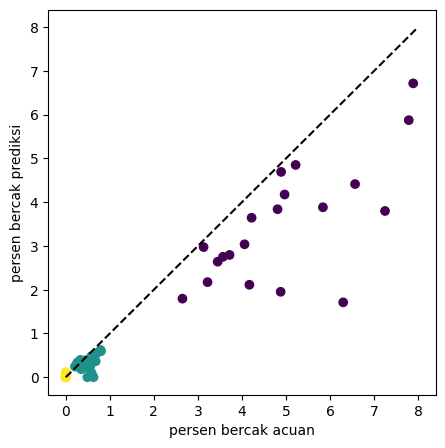


Daun sehat dinilai berbercak : 1
Daun berbercak dinilai sehat : 3


In [12]:
# Kode 5.2 Evaluasi modul bercak.py
import importlib, bercak
importlib.reload(bercak)
PB = {}  # ubah parameter sesuai temuan Anda, mis. {"se_open": 5, "k": 4.0}
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150); plt.show()

# Bahan Tabel 12
print("\nDaun sehat dinilai berbercak :", int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum()))
print("Daun berbercak dinilai sehat :", int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum()))

7 citra salah kelas


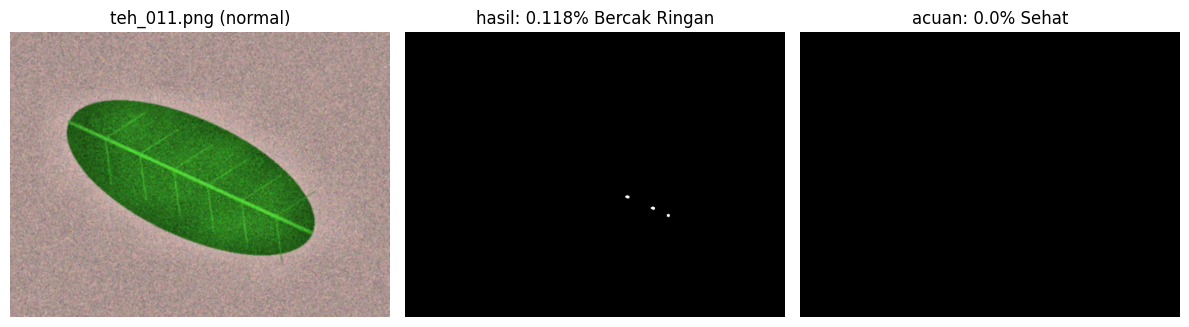

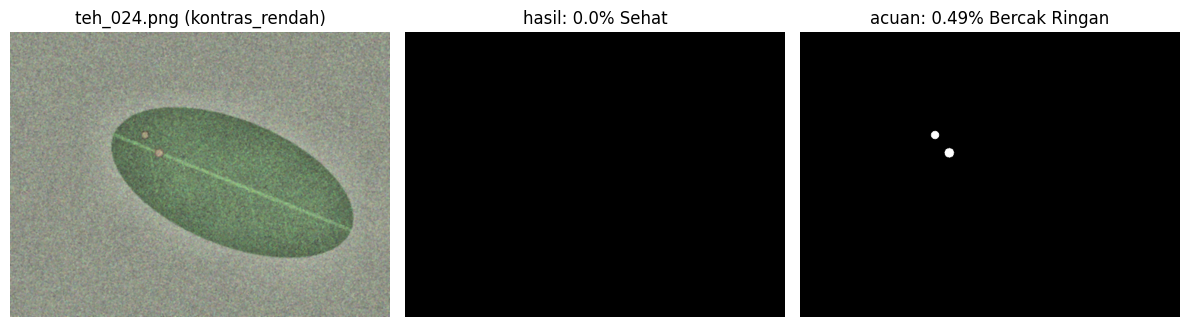

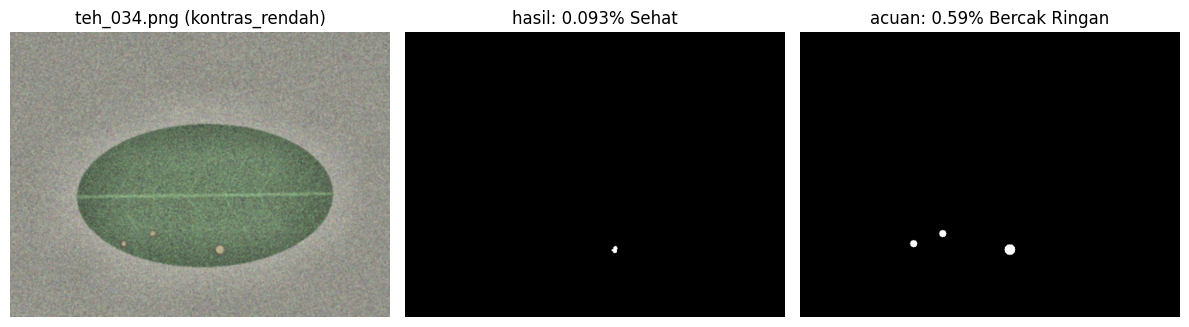

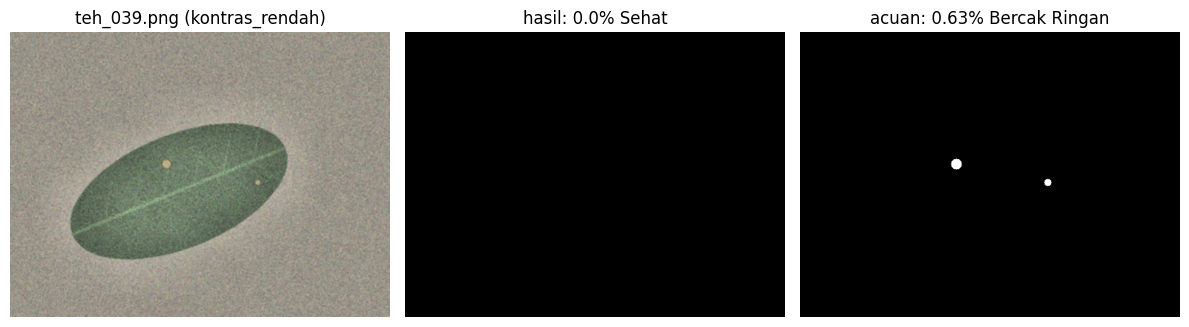

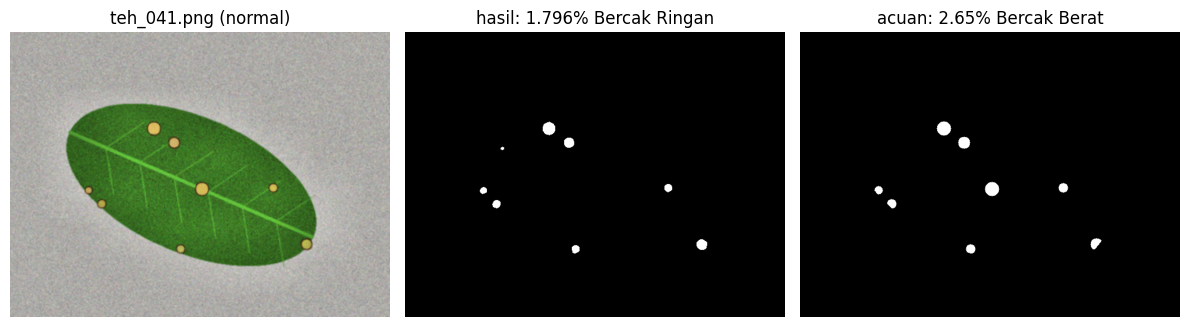

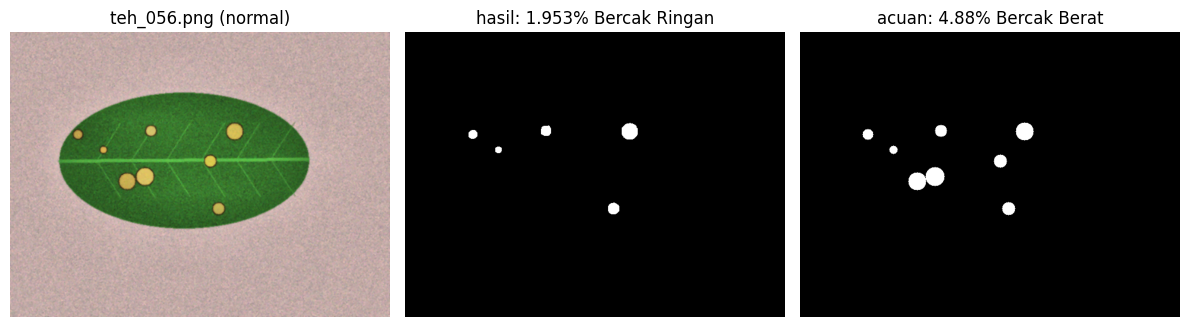

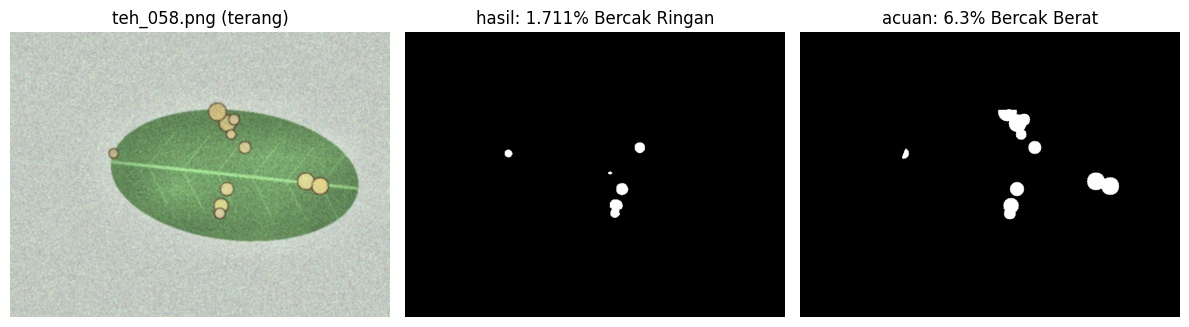

In [13]:
# Langkah 5.3 (Kerjakan sendiri) Analisis kesalahan: citra yang salah kelas
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"{len(salah)} citra salah kelas")
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    tampil([pra_, h["mask_bercak"], mb],
           [f"{r.nama} ({r.kondisi})", f"hasil: {r.persen_prediksi}% {r.kelas_prediksi}",
            f"acuan: {r.persen_acuan}% {r.kelas_acuan}"], ukuran=(12, 3.6))
    # TULIS penyebab kesalahan tiap citra di laporan (praproses / citra biner awal / penyaringan?)

In [14]:
# Langkah 5.4 Kerangka Tabel 13 (isi alasan dan risiko sendiri)
tabel13 = pd.DataFrame({
    "Parameter": ["kanal dan k", "se_bentuk, se_open, se_close", "luas_min",
                  "bulat_min dan rasio_maks", "batas_ringan dan batas_berat"],
    "Nilai final": [f"{bercak.PARAM_BERCAK['kanal']}, {bercak.PARAM_BERCAK['k']}", "", "", "", ""],
    "Alasan dan bukti": ["", "", "", "", ""],
    "Risiko bila salah atur": ["", "", "", "", ""],
})
print(tabel13)

                      Parameter Nilai final Alasan dan bukti Risiko bila salah atur
0                   kanal dan k      2, 4.0                                        
1  se_bentuk, se_open, se_close                                                    
2                      luas_min                                                    
3      bulat_min dan rasio_maks                                                    
4  batas_ringan dan batas_berat                                                    


In [ ]:
# Langkah 5.5 Reprodusibilitas (terminal):
# Restart & Run All kedua notebook, perbarui README.md, lalu:
# git add . && git commit -m "P6: morfologi dan bercak.py" && git tag v0.3-morfologi && git push && git push --tags